# RETAIL SUPERMARKET ANALYSIS: SALES, PROFITABILITY & INVENTORY
**Analytical objective:** uncover operational bottlenecks, calculate true profitability, and optimize inventory turnover. 

In this notebook, I am investigating three years of transactional data (2022, 2023, 2024) alongside current inventory snapshots to find actionable areas where the business is losing margin specifically looking at stockout risks and perishable spoilage.

In [1]:
# libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Notebook environment configuration
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
import warnings
warnings.filterwarnings('ignore')

## 1. Data Ingestion & Initial Inspection
loading the separate datasets and understanding their shape and completeness.

In [3]:
#importing datasets
products = pd.read_csv("dataset/products.csv")
inventory = pd.read_csv("dataset/inventory.csv")

In [4]:
display(products.head())
print("\nProduct Table Info:")
print(products.info())
print(f"\nTotal unique products: {products['product_id'].nunique()}")

,product_id,product_name,category,subcategory,unit_price,unit_of_measure,is_perishable,supplier_id,cost_price,reorder_level
0,1,Aashirvaad Whole Wheat Atta 5kg,Groceries,Staples,265,Pack,False,3,159.0,53
1,2,Aashirvaad Multigrain Atta 5kg,Groceries,Staples,310,Pack,False,3,186.0,39
2,3,Patanjali Chakki Fresh Atta 10kg,Groceries,Staples,380,Pack,False,3,228.0,32
3,4,India Gate Basmati Rice 5kg,Groceries,Staples,580,Pack,False,4,348.0,45
4,5,Lal Qilla Sona Masoori Rice 5kg,Groceries,Staples,420,Pack,False,4,252.0,43



Product Table Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   product_id       200 non-null    int64  
 1   product_name     200 non-null    object 
 2   category         200 non-null    object 
 3   subcategory      200 non-null    object 
 4   unit_price       200 non-null    int64  
 5   unit_of_measure  200 non-null    object 
 6   is_perishable    200 non-null    bool   
 7   supplier_id      200 non-null    int64  
 8   cost_price       200 non-null    float64
 9   reorder_level    200 non-null    int64  
dtypes: bool(1), float64(1), int64(4), object(4)
memory usage: 14.4+ KB
None

Total unique products: 200


In [5]:
#combining the sales datasets(i.e sales 2022,23,24)
sales_files=["dataset/sales_2022.csv","dataset/sales_2023.csv","dataset/sales_2024.csv"]
sales = [pd.read_csv(sales_file) for sales_file in sales_files]
sales_df = pd.concat(sales, ignore_index=True)

In [6]:
# Sanity Check
print(f"2022 Rows: {sales[0].shape[0]:,}")
print(f"2023 Rows: {sales[1].shape[0]:,}")
print(f"2024 Rows: {sales[2].shape[0]:,}")
print(f"Master Sales Rows: {sales_df.shape[0]:,}")

2022 Rows: 364,993
2023 Rows: 364,990
2024 Rows: 365,992
Master Sales Rows: 1,095,975


In [7]:
# Checking for missing values in the master table
print("\nMissing values per column:")
print(sales_df.isnull().sum())


Missing values per column:
transaction_id    0
product_id        0
store_id          0
quantity_sold     0
sale_price        0
timestamp         0
dtype: int64


## 2. Data Transformation & Feature Engineering
The raw sales data only gives us `quantity_sold` and `sale_price`. To discover true business health, I need to know our costs. I will merge the product catalog into the sales data and engineer core financial metrics. I'm also extracting time components to look for seasonality later.

In [8]:
# Parsing timestamps for temporal analysis
sales_df['timestamp'] = pd.to_datetime(sales_df['timestamp']) # timestamp to a datetime object

sales_df['year'] = sales_df['timestamp'].dt.year
sales_df['month'] = sales_df['timestamp'].dt.month
sales_df['day_of_week'] = sales_df['timestamp'].dt.day_name()
sales_df['hour'] = sales_df['timestamp'].dt.hour

In [9]:
# master table sales + products
master_df = sales_df.merge(products, on='product_id', how='left')
master_df.head()

,transaction_id,product_id,store_id,quantity_sold,sale_price,timestamp,year,month,day_of_week,hour,product_name,category,subcategory,unit_price,unit_of_measure,is_perishable,supplier_id,cost_price,reorder_level
0,1,1,1,29,260.94,2022-01-01 08:17:00,2022,1,Saturday,8,Aashirvaad Whole Wheat Atta 5kg,Groceries,Staples,265,Pack,False,3,159.0,53
1,2,2,1,11,317.29,2022-01-01 09:47:00,2022,1,Saturday,9,Aashirvaad Multigrain Atta 5kg,Groceries,Staples,310,Pack,False,3,186.0,39
2,3,3,1,11,370.74,2022-01-01 13:01:00,2022,1,Saturday,13,Patanjali Chakki Fresh Atta 10kg,Groceries,Staples,380,Pack,False,3,228.0,32
3,4,4,1,19,569.52,2022-01-01 16:35:00,2022,1,Saturday,16,India Gate Basmati Rice 5kg,Groceries,Staples,580,Pack,False,4,348.0,45
4,5,5,1,25,418.72,2022-01-01 14:14:00,2022,1,Saturday,14,Lal Qilla Sona Masoori Rice 5kg,Groceries,Staples,420,Pack,False,4,252.0,43


In [10]:
# 3. Engineer financial performance features
master_df['revenue'] = master_df['quantity_sold'] * master_df['sale_price']
master_df['cost_of_goods'] = master_df['quantity_sold'] * master_df['cost_price']
master_df['gross_profit'] = master_df['revenue'] - master_df['cost_of_goods']
master_df['margin_pct'] = (master_df['gross_profit'] / master_df['revenue']) * 100

In [11]:
display(master_df[['timestamp', 'product_name', 'revenue', 'gross_profit', 'margin_pct']].sample(5))

,timestamp,product_name,revenue,gross_profit,margin_pct
1034245,2024-10-31 10:07:00,Limca 750ml,1553.20,593.20,38.192119
176,2022-01-01 14:48:00,Pepsodent Germicheck 150g,257.91,104.91,40.676980
910287,2024-06-29 13:49:00,Ezee Liquid Detergent 500ml,1748.88,704.88,40.304652
542661,2023-06-27 12:53:00,Maaza Mango 600ml,327.12,135.12,41.305943
650273,2023-10-13 08:28:00,Britannia Whole Wheat Bread 400g,675.64,272.44,40.323249


## 3. Exploratory Data Analysis (EDA) & Visualizations
let's explore the key business questions. 

**Question 1: What is our macro financial performance over the 3 years?**

,year,Total_Revenue,Total_Profit,Transactions,Profit_Margin_%
0,2022,7.143685e+08,2.857294e+08,364993,39.997480
1,2023,7.140278e+08,2.856046e+08,364990,39.999084
2,2024,7.125946e+08,2.850413e+08,365992,40.000488


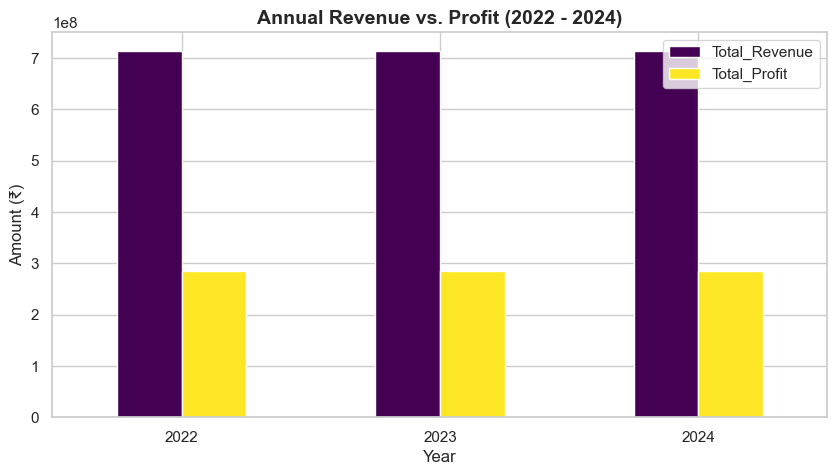

In [12]:
# Aggregate financials by year
yearly_kpi = master_df.groupby('year').agg(
    Total_Revenue=('revenue', 'sum'),
    Total_Profit=('gross_profit', 'sum'),
    Transactions=('transaction_id', 'nunique')
).reset_index()

# Calculate margin
yearly_kpi['Profit_Margin_%'] = (yearly_kpi['Total_Profit'] / yearly_kpi['Total_Revenue']) * 100
display(yearly_kpi)

# Visualization: Revenue vs Profit Year over Year
yearly_kpi.plot(x='year', y=['Total_Revenue', 'Total_Profit'], kind='bar', colormap='viridis', figsize=(10, 5))
plt.title('Annual Revenue vs. Profit (2022 - 2024)', fontsize=14, fontweight='bold')
plt.ylabel('Amount (₹)')
plt.xlabel('Year')
plt.xticks(rotation=0)
plt.show()

**Question 2: Are there seasonal trends we need to prepare for?**

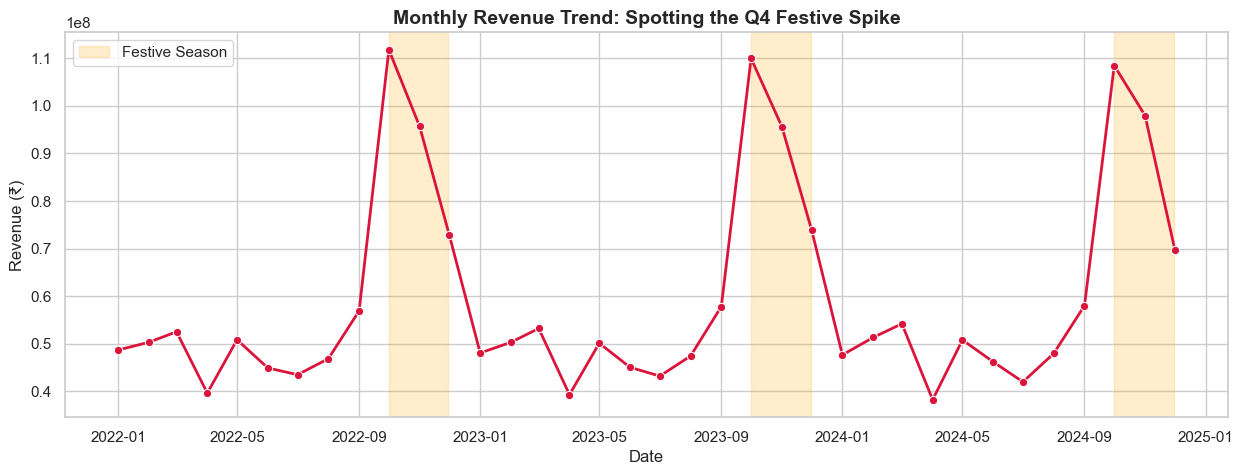

In [13]:
# Create a Year-Month period for continuous plotting
master_df['year_month'] = master_df['timestamp'].dt.to_period('M')
monthly_trend = master_df.groupby('year_month')['revenue'].sum().reset_index()
monthly_trend['year_month'] = monthly_trend['year_month'].dt.to_timestamp()

plt.figure(figsize=(15, 5))
sns.lineplot(data=monthly_trend, x='year_month', y='revenue', marker='o', color='crimson', linewidth=2)
plt.title('Monthly Revenue Trend: Spotting the Q4 Festive Spike', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Revenue (₹)')
plt.axvspan(pd.to_datetime('2022-10-01'), pd.to_datetime('2022-11-30'), color='orange', alpha=0.2, label='Festive Season')
plt.axvspan(pd.to_datetime('2023-10-01'), pd.to_datetime('2023-11-30'), color='orange', alpha=0.2)
plt.axvspan(pd.to_datetime('2024-10-01'), pd.to_datetime('2024-11-30'), color='orange', alpha=0.2)
plt.legend()
plt.show()

**Question 3: What categories and subcategories are driving our sales?**

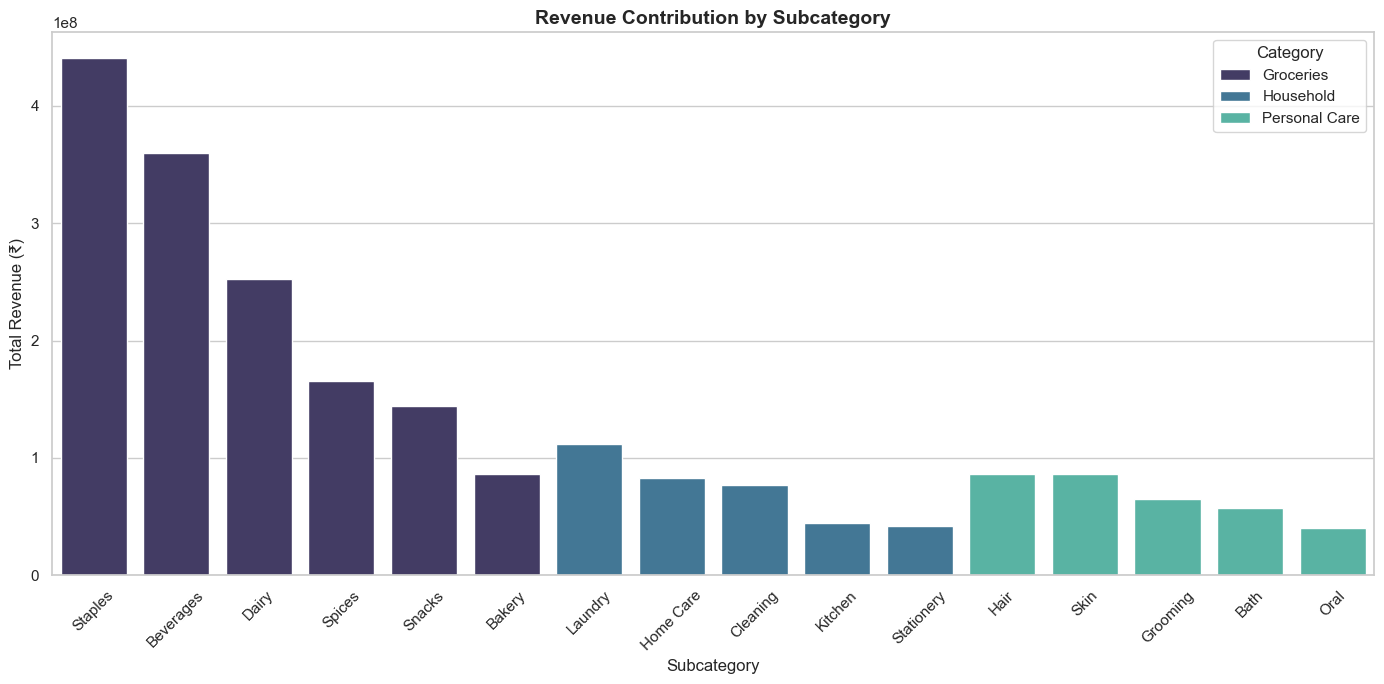

In [14]:
# Group by Category and Subcategory
category_breakdown = master_df.groupby(['category', 'subcategory'])['revenue'].sum().reset_index()
category_breakdown = category_breakdown.sort_values(by=['category', 'revenue'], ascending=[True, False])

plt.figure(figsize=(14, 7))
sns.barplot(data=category_breakdown, x='subcategory', y='revenue', hue='category', dodge=False, palette='mako')
plt.title('Revenue Contribution by Subcategory', fontsize=14, fontweight='bold')
plt.xlabel('Subcategory')
plt.ylabel('Total Revenue (₹)')
plt.xticks(rotation=45)
plt.legend(title='Category')
plt.tight_layout()
plt.show()

**Question 4: Supply Chain Health - Are we at risk of stockouts?**

In [15]:
# Merge inventory with product reorder levels
inv_risk = inventory.merge(products[['product_id', 'product_name', 'reorder_level']], on='product_id', how='left')

# Calculate the gap between current stock and the reorder trigger
inv_risk['stock_status'] = inv_risk['stock_level'] - inv_risk['reorder_level']

# Filter for products in the danger zone
critical_stock = inv_risk[inv_risk['stock_status'] < 0].sort_values(by='stock_status')

print(f"Warning: {len(critical_stock)} out of {len(products)} products are below reorder levels.")
display(critical_stock[['product_name', 'stock_level', 'reorder_level', 'stock_status']].head(10))

,product_name,stock_level,reorder_level,stock_status
63,Dabur Real Mango Juice 1L,21,48,-27
8,Fortune Urad Dal 1kg,22,48,-26
44,Bingo Mad Angles 90g,21,41,-20
193,Gillette Mach3 Razor,13,25,-12
57,Lipton Green Tea 25 bags,21,32,-11
115,Scotch Brite Steel Scrubber 3pcs,17,26,-9
84,Maggi Green Chilli Sauce 200g,22,31,-9
156,Head Shoulders AntiDandruff 340ml,19,28,-9
165,Nivea Soft Moisturising Cream 100ml,13,21,-8
162,Livon Hair Serum 100ml,19,26,-7


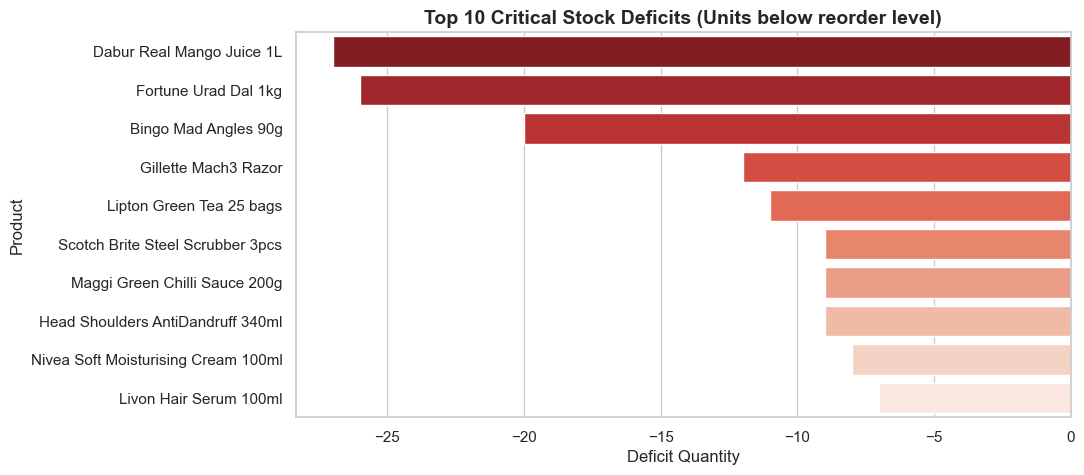

In [16]:
# Visualization: Top 10 most critical stockouts
plt.figure(figsize=(10, 5))
sns.barplot(data=critical_stock.head(10), x='stock_status', y='product_name', palette='Reds_r')
plt.title('Top 10 Critical Stock Deficits (Units below reorder level)', fontsize=14, fontweight='bold')
plt.xlabel('Deficit Quantity')
plt.ylabel('Product')
plt.show()

In [17]:
# Basket Analysis (AOV & B2B Outliers)
basket_analysis = master_df.groupby('transaction_id').agg(
    items_purchased=('quantity_sold', 'sum'),
    order_value=('revenue', 'sum')
)
print("--- Basket Analysis ---")
display(basket_analysis.describe())

--- Basket Analysis ---


,items_purchased,order_value
count,1.095975e+06,1.095975e+06
mean,1.485167e+01,1.953503e+03
std,1.330222e+01,2.718576e+03
min,1.000000e+00,1.944000e+01
25%,6.000000e+00,5.858700e+02
50%,1.100000e+01,1.142760e+03
75%,2.000000e+01,2.212185e+03
max,2.300000e+02,9.280523e+04


In [18]:
# Supplier Dependency Risk
supplier_perf = master_df.groupby('supplier_id').agg(
    total_revenue=('revenue', 'sum'),
    products_supplied=('product_id', 'nunique')
).sort_values(by='total_revenue', ascending=False)

print("--- Top Suppliers by Revenue ---\n")
display(supplier_perf.head())

--- Top Suppliers by Revenue ---



,total_revenue,products_supplied
supplier_id,,
2,6.264584e+08,68
4,3.570311e+08,22
7,2.530725e+08,27
3,2.114133e+08,8
1,1.660224e+08,13


In [19]:
# Inventory Expiry Audit
inventory['expiry_date'] = pd.to_datetime(inventory['expiry_date'])
current_date = pd.to_datetime('today') # Or set to a static audit date like '2026-10-13'
inventory['days_to_expiry'] = (inventory['expiry_date'] - current_date).dt.days

expired = inventory[inventory['days_to_expiry'] < 0]
expiring_soon = inventory[(inventory['days_to_expiry'] >= 0) & (inventory['days_to_expiry'] <= 90)]

print(f"ALERT: {len(expired)} items are already expired.")
print(f"\nALERT: {len(expiring_soon)} items expire in the next 90 days.")

ALERT: 16 items are already expired.

ALERT: 30 items expire in the next 90 days.


## Finalizing Data for BI Tools

In [20]:
# Export for BI tools
master_df.to_csv('cleaned_master_sales.csv', index=False)
print("Data successfully exported as 'cleaned_master_sales.csv'")

Data successfully exported as 'cleaned_master_sales.csv'


In [23]:
# 100-row random sample for GitHub repository
sample_df = master_df.sample(n=100, random_state=42) 
sample_df.to_csv('sample_master_sales.csv', index=False)
print("100-row sample saved as 'sample_master_sales.csv' ")

100-row sample saved as 'sample_master_sales.csv' 


# KEY FINDINGS

**Executive Summary**

* Total Revenue (2022–2024): ₹2.14 Billion

* Total Profit: ₹856.3 Million

* Total Transaction Volume: 1,095,975 individual sales

* Store Consistency: Store operations are highly standardized, with all 5 locations generating near-identical revenue across the three-year period (ranging tightly between ₹427.5M and ₹428.8M per store).

**Sales & Seasonality Trends**

* Flat YoY Growth: Year-over-year revenue is stagnant but stable. (2022: ₹714.3M | 2023: ₹714.0M | 2024: ₹712.5M).

* The Q4 Festive Spike: There is extreme seasonality in the business. Over the 3-year period, October (₹330.1M) and November (₹289.2M) generated disproportionately higher sales than any other months, closely aligning with the Indian festive season (Diwali/Dussehra).

* Summer Slump: April (₹117.2M) and July (₹128.7M) represent the weakest periods for the business, requiring heavy promotional intervention to stabilize cash flow.

**Product & Supplier Performance**

* Category Dominance: Groceries is the absolute financial backbone of the business, accounting for ₹1.44 Billion (67.6%) of total revenue. Household (₹357.6M) and Personal Care (₹334.7M) make up the remaining third.

* Top Subcategories: Within Groceries, Staples (₹440.7M) and Beverages (₹360.2M) are the highest-grossing subcategories.

* Top Products: The top 5 revenue-generating items are everyday essentials, not luxury goods:

    1. India Gate Basmati Rice 5kg (₹69.2M)

    2. Patanjali Cow Ghee 1L (₹67.8M)

    3. DiSano Extra Virgin Olive Oil 500ml (₹57.7M)

    4. Lal Qilla Sona Masoori Rice 5kg (₹50.6M)

    5. Patanjali Chakki Fresh Atta 10kg (₹45.2M)

* Supplier Risk: The business has a high dependency on Supplier #2, who provides 68 unique products and is responsible for ₹626.4 Million (29.2%) of total cumulative revenue.

**Customer Shopping Behavior**

* Day of Week: Weekends dictate the business model. Saturday (₹402.2M) and Sunday (₹372.6M) are the strongest days, generating nearly double the volume of a standard mid-week day like Monday (₹254.5M).

* Time of Day: The Afternoon (12:00 PM – 4:59 PM) is the peak shopping window, accounting for ₹752.1M in sales, followed by the Evening (5:00 PM – 8:59 PM) at ₹676.5M. Mornings and nights are significantly slower.

* Basket Analysis (AOV): The average transaction contains 15 items with an Average Order Value (AOV) of ₹1,953.

* B2B / Whale Outliers: While the average basket is small, the maximum recorded transaction value is ₹92,805 (230 items), indicating the presence of bulk B2B purchasers (e.g., local restaurants, caterers, or small vendors) utilizing the supermarket for wholesale needs.

**Operational & Supply Chain Risks**
* Out-of-Stock Risk: Currently, 20 products (10% of the catalog) are sitting below their designated safe reorder_level in the inventory. This presents an immediate risk of stockouts and unfulfilled customer demand.

* Expiry & Compliance Audit: A critical health-code and financial write-off risk exists on the shelves. As of the current audit date:

* 16 products have already passed their expiry_date but remain in active inventory.

* 30 products will expire within the next 90 days, requiring immediate liquidation via discount promotions to recover capital before total spoilage.